# `ratio_study` - 02 Spatial

Ratio maps and spatial autocorrelation. Needs the `spatial` extra.

| Notebook | Covers |
|---|---|
| [01 Basics](01_basics.ipynb) | Sections 1-2: indicators, confidence intervals, compliance checks, IQR trimming, charts, comparisons |
| [02 Spatial](02_spatial.ipynb) | Section 3: ratio maps, Moran's I, hot/cold spots, the VEM map |
| [03 Reporting](03_reporting.ipynb) | Section 4: PDF / XLSX / CSV / PNG output |
| [04 Advanced diagnostics](04_advanced_diagnostics.ipynb) | Sections 5 and 7: ML / SHAP inequity diagnostics and sales-chasing detection |
| [05 Vertical equity](05_vertical_equity.ipynb) | Section 6: VEI, the Vertical Equity Panel, VEM, the Gini family |

All five use the anonymised sample dataset bundled with the package - no data preparation required.
Section numbers are kept from the original single-notebook tour so cross-references still line up.

## Setup

```
pip install "ratio_study[spatial]"
```

The spatial functions expect `latitude` / `longitude` columns (override with `lat_col` / `long_col`) and a ratio column in the frame - the setup cell adds `asr`.

**Note on the data:** the sample's coordinates are random placeholders, not real locations (see the note in 3.1).

In [1]:
# Uncomment on first run.
# %pip install "ratio_study[spatial]"

In [2]:
import ratio_study as rs
import pandas as pd
import numpy as np
from pathlib import Path
from ratio_study import spatial

# inline plotting must be enabled AFTER importing ratio_study
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

sample_df = rs.load_sample_dataset()

MARKET_VALUE = 'time_adjusted_sale_price'   # the market value proxy
ASSESSMENT   = 'assessment_value_new'       # the value under test (current CAMA model)

sample_df['asr'] = sample_df[ASSESSMENT] / sample_df[MARKET_VALUE]   # ratio column, needed by the spatial and VE functions

print('ratio_study version:', rs.__version__)
print(f'{len(sample_df):,} sales, {sample_df.shape[1]} columns')

ratio_study version: 0.4.5
12,583 sales, 20 columns


---
# 3. Spatial special features

Assessment inequity is rarely spread evenly across a jurisdiction - it concentrates. Two neighbourhoods with identical CODs can be very different problems if one sits in the middle of a contiguous block of over-assessment.

The Standard lists maps among the visualisations useful in a ratio study, and asks oversight agencies to stratify geographically. These tools do both.


## 3.1 Ratio maps

`ratio_map()` draws one dot per sale on an interactive `lonboard` map, coloured by how far its ratio has drifted from the sample's median. Five colours, in every scheme: **grey** for the central mass, light orange / light blue for the ring that has drifted off the median, and **red / dark blue** for the far tails. The palette avoids red-yellow-green so it stays readable under red-blindness.

`colour_code_by` chooses what "drifted" means:

| Scheme | Bands are | Use for |
|---|---|---|
| `'iqr'` *(default)* | 1.5 and 3.0 IQR fences - the same rule as the outlier filter in the basics notebook | seeing exactly what the study would trim |
| `'mad'` | median-absolute-deviation multiples | samples whose quartiles are themselves pulled about |
| `'standard'` | fixed shares of the median (10 % / 25 %) | comparing jurisdictions - "10 % off level" means the same on every map |
| `'quantile'` | fixed 80 % / 120 % tails plus `n_bins - 2` adaptive bins | maps built against the earlier scheme; the only scheme `n_bins` applies to |

With `groupby='neighbourhood'`, each neighbourhood is coloured by its **median** ratio and the colour scheme is applied to those medians. Without it, every sale is coloured by its own ratio.

**A notebook cell is a poor container for a map.** Three controls sit above every map to work around that:

| Control | What it does |
|---|---|
| **Open in browser** | Writes a self-contained HTML map and opens it in your default browser - the way to get a genuinely full-window map. The file survives the kernel, so it can be emailed or attached to a report. |
| **Taller** / **Shorter** | Step the height by 200 px in place, down to a 200 px floor. |

`height=` sets the starting height: pixels (`750`) or any CSS length (`'85vh'`). Taller/Shorter only apply to pixel heights.

`dot_size` and `opacity` tune dense or sparse rolls: raise `dot_size` when dots vanish at the fitted zoom, lower it when they merge into a blob.

In [3]:
# Neighbourhood medians, default IQR colouring.
spatial.ratio_map(df=sample_df,
                  column='asr',
                  groupby='neighbourhood',
                  height=750)     # click 'Open in browser' for a full-window map

[interactive map - run the notebook to view it]

Without `groupby`, each sale carries its own ratio. `colour_code_by='standard'` uses fixed bands, so the colours mean the same thing on any jurisdiction's map.

In [4]:
spatial.ratio_map(df=sample_df,
                  column='asr',
                  colour_code_by='standard',
                  standard_bands=(0.10, 0.25),
                  dot_size=25,
                  opacity=0.5,
                  height=750)

[interactive map - run the notebook to view it]

The same export is callable from a script, which is how you pick a specific browser:

```python
import webbrowser

panel = spatial.ratio_map(df=sample_df, column='asr', groupby='neighbourhood')
path = spatial.open_map_in_browser(panel, open_browser=False)   # just write it
webbrowser.get('firefox').open(path.as_uri())                   # ... then choose
```

> **About this sample.** The latitude and longitude columns are **randomly assigned**, only so the spatial tools have coordinates to run on. They are not realistic - many homes fall on the Ottawa River - and bear no relation to where a property really is. The ratios are unrelated to location, so expect a mostly grey map and a Moran's I near zero below. That is what the sample is built to show, not evidence about a model. On a roll with a real spatial problem the same calls show orange/red and blue clusters and a significant positive I.

## 3.2 Spatial autocorrelation: Moran's I

**Moran's I** asks whether high ratios sit next to other high ratios more than chance
allows. It runs from −1 (perfect dispersion) through 0 (random) to +1 (perfect clustering).

A significantly positive I means the model has missed something *geographic* — a location
effect it is not capturing — and that the fix is a modelling fix, not a per-property one.
It is the diagnostic behind the Standard's advice to resolve inequity between geographic areas
before testing vertical equity.

`moran_i()` is the indicator form: statistics as a dict, for pipelines and compliance
tables.

In [5]:
moran = rs.moran_i(sample_df, 'asr', k=8, permutations=999)

pd.Series(moran).to_frame('value')

,value
I,0.005550
EI,-0.000079
p_norm,0.183998
z_norm,1.328545
p_rand,0.183927
z_rand,1.328760
p_sim,0.099000
z_sim,1.346518
n,12583.000000


`spatial.global_moran()` is the presentation form: the same statistic with a Moran
scatterplot, a reference-distribution plot, and a written interpretation of the I, Z and
p values.

Please proceed, no action required. A Global Moran's I value of 0.01 indicates no spatial autocorrelation. The Z value (2.34) and P value (0.0192), under the randomisation hypothesis, indicate that the result is statistically insignificant. 

I: 0.005799248815495459 
EI: -7.947862025115244e-05 
p_norm: 0.019261184741186314 
z_norm: 2.340437058082986 
VI_norm: 6.309177088719825e-06 
seI_norm: 0.0025118075341713235 
p_rand: 0.019241717270858508 
z_rand: 2.340814645042624 
VI_rand: 6.3071418392707625e-06 
seI_rand: 0.002511402365068322 
EI_sim: -0.00012667827614589418 
p_sim: 0.005 
z_sim: 2.435397713966174 
p_z_sim 0.007437714804120817 
permutations: 999
z_norm: 0.009630592370593157


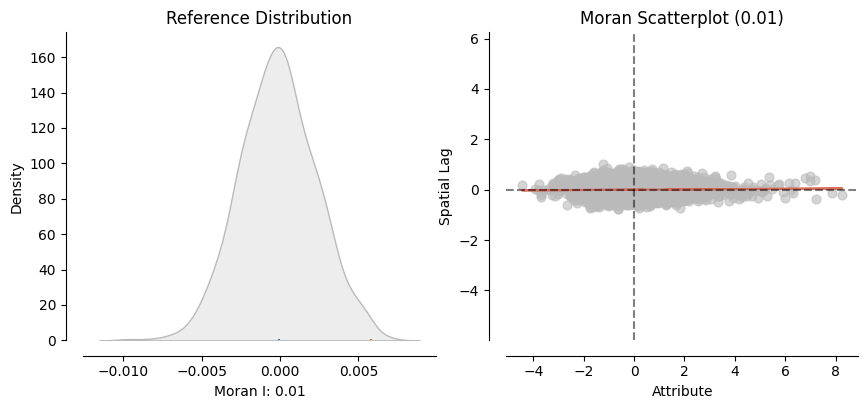

In [6]:
spatial.global_moran(df=sample_df, ratio='asr')

### Local Moran / Getis–Ord: *where* are the hot and cold spots?

Global Moran's I gives one number for the whole jurisdiction. The **local** statistic gives
one per sale, which is what you actually need to act:

- **Hot spots** — clusters of over-assessment (high ratios surrounded by high ratios)
- **Cold spots** — clusters of under-assessment
- Neither — no significant local clustering

Everything outside the hot and cold spots is where the model is behaving.

In [7]:
# Same controls and the same `height` argument as the ratio map above.
spatial.local_moran(df=sample_df, ratio='asr', height=750)

[interactive map - run the notebook to view it]

## 3.3 Mapping the VEM verdict

Sections 3.1 and 3.2 map the ratio itself. `vem_map()` maps something different: the
**verdict of the VEM** (section 6.4) for each sale — whether the local median ASR for that
sale's *price band* sits inside the acceptable band.

| Colour | Meaning |
|---|---|
| **green** | the local median is within `acceptable_inequity_level` of the overall median |
| **red** | the local median is above the band — an over-assessed stretch of the value range |
| **blue** | the local median is below the band — an under-assessed stretch |

The grouping is by **value, not by location**, which is what makes the map interesting: if
the colours come out spatially scattered, a mis-assessed price band is spread across the
jurisdiction and the fix is a value-curve fix. If they come out geographically clustered,
then a price band that is mis-assessed also happens to sit somewhere in particular — a
location effect the model has missed, and the same conclusion Moran's I reaches from the
other direction.

At the default 10% band this model is fully acceptable, so every point is green — a true
result, but a dull map. Narrowing the band to 2% shows the mechanism.

In [8]:
spatial.vem_map(df=sample_df,
                assessment_header=ASSESSMENT,
                market_value_header=MARKET_VALUE,
                quantiles=20,
                acceptable_inequity_level=0.02,   # deliberately strict, to show the colours
                conf_level=0.90,
                height=750)

[interactive map - run the notebook to view it]

The legend carries the counts and shares, so "red" can be read as a proportion of the roll
rather than an impression.

`strict=True` switches from the point estimate to `ci_out_of_bounds`: a stretch then has to
have its **whole local-median confidence interval** outside the band before it is coloured.
That is the same test the VEM verdict itself applies, so `strict=True` maps exactly what the
indicator reports — and it is the conservative reading the Standard asks for throughout,
where a point estimate is an indication and the interval is the proof.

In [9]:
spatial.vem_map(df=sample_df,
                assessment_header=ASSESSMENT,
                market_value_header=MARKET_VALUE,
                quantiles=20,
                acceptable_inequity_level=0.02,
                conf_level=0.90,
                strict=True,                      # whole interval must clear the band
                height=750)

[interactive map - run the notebook to view it]

Fewer sales are flagged under `strict=True`, because confirming an excursion is a higher bar
than observing one. The gap between the two maps is the set of stretches where the data hints
at inequity but cannot demonstrate it — worth watching next cycle, not worth acting on now.

The map takes the same controls as the others: **Open in browser** for a full-window view,
**Taller** / **Shorter** to resize in place.

---
**Next:** [03 Reporting](03_reporting.ipynb) | [05 Vertical equity](05_vertical_equity.ipynb) for the VEM that section 3.3 maps.